# Homework 01 – Denoising Autoencoder on MNIST
**Model: Small Kernel CNN** (Conv2D with small kernels, encoder → bottleneck → decoder)

Teacher's setup: MNIST 70,000 · sizes 2500 & 5000 · split 70/20/10 (train/test/val) · 15% noise on test · epochs 50 & 100 · lr 0.01 · same seed everywhere.

> Works on CPU too: the data is small (2,500 / 5,000 images), so the 4 runs finish in a few minutes.

## 1. Imports + seed

In [1]:
import os, zipfile, glob, gzip, struct, random
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

SEED = 42
def set_seed(s=SEED):
    os.environ["PYTHONHASHSEED"] = str(s)
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
set_seed()
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TF 2.21.0 | GPU: []


## 2. Unzip & load `mnist_dataset.zip`
The loader auto-detects the format inside the zip (image folders, CSV, IDX, or npz).

In [2]:
# your zip is in Colab's root folder ("/"), so look there first, then /content, or local / Pictures
CANDIDATES = [
    "mnist_dataset.zip",
    r"C:\Users\Rosa\Pictures\mnist_dataset.zip",
    "/mnist_dataset.zip",
    "/content/mnist_dataset.zip",
]
ZIP_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
assert ZIP_PATH, "mnist_dataset.zip not found - check the Files panel for its location"
print("using zip:", ZIP_PATH)
DATA_DIR = "mnist_data"

# ---- check the file before unzipping ----
size_mb = os.path.getsize(ZIP_PATH) / 1e6
with open(ZIP_PATH, "rb") as f:
    head = f.read(8)
print(f"file size: {size_mb:.2f} MB | first bytes: {head}")
# real MNIST zips are roughly 10-110 MB; a zip must start with b'PK'

import tarfile, shutil
if not os.path.exists(DATA_DIR):
    if zipfile.is_zipfile(ZIP_PATH):
        with zipfile.ZipFile(ZIP_PATH) as z:
            z.extractall(DATA_DIR)
    elif tarfile.is_tarfile(ZIP_PATH):
        with tarfile.open(ZIP_PATH) as t:
            t.extractall(DATA_DIR)
    elif head[:2] == b"\x1f\x8b":                       # plain gzip
        os.makedirs(DATA_DIR, exist_ok=True)
        with gzip.open(ZIP_PATH) as fi, open(os.path.join(DATA_DIR, "data.bin"), "wb") as fo:
            shutil.copyfileobj(fi, fo)
    else:
        raise RuntimeError(
            "This file is NOT a valid zip (upload was probably cut off, or it is an HTML/other file). "
            "Delete it from the Files panel, re-upload it, and wait until the upload circle finishes. "
            "Or use the Keras MNIST fallback in the next cell.")

# quick look at what is inside
shown = 0
for root, dirs, files in os.walk(DATA_DIR):
    print(root, "| files:", len(files), "| e.g.", files[:3])
    shown += 1
    if shown >= 25: break

using zip: mnist_dataset.zip
file size: 23.11 MB | first bytes: b'PK\x03\x04-\x00\x00\x00'
mnist_data | files: 4 | e.g. ['t10k-images.idx3-ubyte', 't10k-labels.idx1-ubyte', 'train-images.idx3-ubyte']
mnist_data\t10k-images-idx3-ubyte | files: 1 | e.g. ['t10k-images-idx3-ubyte']
mnist_data\t10k-labels-idx1-ubyte | files: 1 | e.g. ['t10k-labels-idx1-ubyte']
mnist_data\train-images-idx3-ubyte | files: 1 | e.g. ['train-images-idx3-ubyte']
mnist_data\train-labels-idx1-ubyte | files: 1 | e.g. ['train-labels-idx1-ubyte']


### 2b. (Fallback) Only if your zip is broken – load MNIST from Keras instead
Skip this cell if the zip loaded fine. It gives the same 70,000 images, so results are comparable.

In [3]:
USE_KERAS_FALLBACK = False       # set True only if the zip cannot be read
if USE_KERAS_FALLBACK:
    (a, b), (c, d) = keras.datasets.mnist.load_data()
    X_raw, Y = np.concatenate([a, c]), np.concatenate([b, d])
    print("loaded from keras:", X_raw.shape)

In [4]:
def _read_idx(path):
    op = gzip.open if path.endswith(".gz") else open
    with op(path, "rb") as f:
        magic = struct.unpack(">I", f.read(4))[0]
        nd = magic & 0xFF
        shape = struct.unpack(">" + "I" * nd, f.read(4 * nd))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(shape)

def load_mnist_any(root):
    """Return images (N,28,28) uint8 and labels (N,) from whatever format the zip uses."""
    allf = [p for p in glob.glob(os.path.join(root, "**", "*"), recursive=True) if os.path.isfile(p)]
    low = lambda p: p.lower()

    # 1) npz
    npz = [p for p in allf if low(p).endswith(".npz")]
    if npz:
        d = np.load(npz[0])
        if "x_train" in d:
            return np.concatenate([d["x_train"], d["x_test"]]), np.concatenate([d["y_train"], d["y_test"]])

    # 2) IDX files
    idx_img = sorted(p for p in allf if "idx3" in low(p))
    idx_lbl = sorted(p for p in allf if "idx1" in low(p))
    # Deduplicate if zip contains both dotted and dashed duplicates
    if len(idx_img) > 2:
        idx_img = sorted(p for p in idx_img if "." in os.path.basename(p)) or idx_img[:2]
    if len(idx_lbl) > 2:
        idx_lbl = sorted(p for p in idx_lbl if "." in os.path.basename(p)) or idx_lbl[:2]

    if idx_img and idx_lbl:
        return (np.concatenate([_read_idx(p) for p in idx_img]),
                np.concatenate([_read_idx(p) for p in idx_lbl]))

    # 3) CSV (label + 784 pixels)
    csvs = [p for p in allf if low(p).endswith(".csv")]
    if csvs:
        dfs = [pd.read_csv(p) for p in csvs]
        df = pd.concat(dfs, ignore_index=True)
        lab = "label" if "label" in df.columns else df.columns[0]
        y = df[lab].values.astype(int)
        x = df.drop(columns=[lab]).values.astype(np.uint8).reshape(-1, 28, 28)
        return x, y

    # 4) image folders  (…/<digit>/img.png)
    from PIL import Image
    imgs = [p for p in allf if low(p).endswith((".png", ".jpg", ".jpeg", ".bmp"))]
    if imgs:
        xs, ys = [], []
        for p in imgs:
            lbl = os.path.basename(os.path.dirname(p))
            if not lbl.isdigit():
                continue
            im = Image.open(p).convert("L")
            if im.size != (28, 28): im = im.resize((28, 28))
            xs.append(np.array(im, dtype=np.uint8)); ys.append(int(lbl))
        if xs:
            return np.stack(xs), np.array(ys)
    raise RuntimeError("Could not detect the dataset format - run the cell above and check the folder tree.")

if not USE_KERAS_FALLBACK:
    X_raw, Y = load_mnist_any(DATA_DIR)
X = (X_raw.astype("float32") / 255.).reshape(-1, 28, 28, 1)   # CNN keeps the 2-D shape
print("images:", X.shape, X.dtype, "| labels:", Y.shape)
print("pixel range:", X.min(), X.max(), "| classes:", np.unique(Y))
print("total:", len(X), "(teacher says 70,000)")
print("all per digit:", np.bincount(Y))

images: (70000, 28, 28, 1) float32 | labels: (70000,)
pixel range: 0.0 1.0 | classes: [0 1 2 3 4 5 6 7 8 9]
total: 70000 (teacher says 70,000)
all per digit: [6903 7877 6990 7141 6824 6313 6876 7293 6825 6958]


## 3. Splits (70/20/10) + 15% noise on the test set

In [5]:
def make_splits(n):
    idx, _ = train_test_split(np.arange(len(X)), train_size=n, stratify=Y, random_state=SEED)
    Xs, Ys = X[idx], Y[idx]
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(Xs, Ys, train_size=0.7, stratify=Ys, random_state=SEED)
    # remaining 30% -> 20% test (2/3) and 10% validation (1/3)
    X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=2/3, stratify=y_tmp, random_state=SEED)
    return X_tr, y_tr, X_val, y_val, X_te, y_te

def add_noise(x, level=0.15, seed=SEED):
    rng = np.random.default_rng(seed)
    return np.clip(x + rng.normal(0, level, x.shape), 0, 1).astype("float32")

for n in [2500, 5000]:
    s = make_splits(n)
    print(n, "-> train", len(s[0]), "| val", len(s[2]), "| test", len(s[4]))

2500 -> train 1750 | val 250 | test 500
5000 -> train 3500 | val 500 | test 1000


## 4. Model: Small Kernel CNN Denoising Autoencoder (Streamlined 6-Layer Modular Architecture)
Streamlined architecture with separated **Encoder** and **Decoder** submodels:
- **Encoder (3 layers)**: `Conv2D(32, 3)` -> `MaxPooling2D(2)` -> `Conv2D(64, 3)` bottleneck (`14×14×64`).
- **Decoder (3 layers)**: `UpSampling2D(2)` -> `Conv2D(32, 3)` -> `Conv2D(1, 3, sigmoid)` reconstruction (`28×28×1`).
- **Purpose**:
  1. **Denoising**: Full autoencoder maps noisy input $\tilde{X} \to X$.
  2. **Encoder Extraction**: Access `model.get_layer('encoder')` for latent feature representation.


In [6]:
KERNEL = (3, 3)

def build_encoder():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, KERNEL, padding="same", name="enc_conv"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2), padding="same", name="enc_pool"),
        layers.Conv2D(64, KERNEL, padding="same", name="latent_bottleneck"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
    ], name="encoder")

def build_decoder():
    return keras.Sequential([
        layers.Input(shape=(14, 14, 64)),
        layers.UpSampling2D((2, 2), name="dec_upsample"),
        layers.Conv2D(32, KERNEL, padding="same", name="dec_conv"),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(1, KERNEL, activation="sigmoid", padding="same", name="reconstruction"),
    ], name="decoder")

def build(lr=0.01):
    encoder = build_encoder()
    decoder = build_decoder()
    m = keras.Sequential([encoder, decoder], name="small_kernel_cnn_dae")
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy")
    return m

m = build()
m.summary()
print("\n--- Encoder Submodel ---")
m.get_layer("encoder").summary()
print("\n--- Decoder Submodel ---")
m.get_layer("decoder").summary()
print("Input:", m.input_shape, "| Bottleneck:", m.get_layer("encoder").output_shape, "| Output:", m.output_shape)

Model: "small_kernel_cnn_dae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Sequential)            │ (None, 14, 14, 64)     │        19,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Sequential)            │ (None, 28, 28, 1)      │        18,881 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,081 (148.75 KB)

 Trainable params: 37,825 (147.75 KB)

 Non-trainable params: 256 (1.00 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dec_upsample (UpSampling2D)     │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_conv (Conv2D)               │ (None, 28, 28, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Conv2D)         │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,881 (73.75 KB)

 Trainable params: 18,817 (73.50 KB)

 Non-trainable params: 64 (256.00 B)

Input: (None, 28, 28, 1) | Bottleneck: (None, 14, 14, 64) | Output: (None, 28, 28, 1)


## 5. Sanity checks (same idea as the sample)

In [7]:
X_tr0 = make_splits(2500)[0]
out = m.predict(X_tr0[:100], verbose=0)
print("output:", out.shape, out.min(), out.max())     # values must be in 0..1

# Verify encoder latent code extraction
codes0 = m.get_layer("encoder").predict(X_tr0[:100], verbose=0)
print("encoder bottleneck code shape:", codes0.shape)  # (100, 14, 14, 64)

# can the model overfit 64 images? (loss should drop a lot)
set_seed()
m_chk = build(lr=0.001)
small = X_tr0[:64]
h = m_chk.fit(small, small, epochs=300, batch_size=64, verbose=0)
print("overfit-64  start:", h.history["loss"][0], "| end:", h.history["loss"][-1])

mean_img = X_tr0.mean(0)
print("mean-image baseline MSE:", np.mean((X_tr0 - mean_img) ** 2), "(model must beat this)")


output: (100, 28, 28, 1) 0.4415577 0.51138085
encoder bottleneck code shape: (100, 14, 14, 64)
overfit-64  start: 0.8372237682342529 | end: 0.061259910464286804
mean-image baseline MSE: 0.06715421 (model must beat this)


## 6. Train all 4 runs (size 2500/5000 × epochs 50/100)

In [8]:
def run_all(noisy_train=True, lr=0.01):
    out = {}
    for n in [2500, 5000]:
        X_tr, y_tr, X_val, y_val, X_te, y_te = make_splits(n)
        X_te_noisy = add_noise(X_te)                       # 15% noise on TEST only
        if noisy_train:
            # Denoising autoencoder: map noisy inputs to clean targets
            X_in, X_vin = add_noise(X_tr, seed=SEED+1), add_noise(X_val, seed=SEED+2)
        else:
            X_in, X_vin = X_tr, X_val
        for ep in [50, 100]:
            set_seed()                                     # same seed for every run
            model = build(lr)
            h = model.fit(X_in, X_tr, validation_data=(X_vin, X_val),
                          epochs=ep, batch_size=64, shuffle=True, verbose=0)
            recon = model.predict(X_te_noisy, verbose=0)
            # Soft-threshold residual background speckles (< 0.08) for maximum clarity and classification accuracy
            recon_clean = np.where(recon < 0.08, 0.0, recon).astype("float32")
            mse = np.mean((recon_clean - X_te) ** 2)
            encoder = model.get_layer("encoder")
            out[(n, ep)] = dict(model=model, encoder=encoder, hist=h.history, recon=recon_clean,
                                noisy=X_te_noisy, clean=X_te, y_te=y_te, mse=mse)
            print(f"n={n} ep={ep} | train={h.history['loss'][-1]:.4f} "
                  f"val={h.history['val_loss'][-1]:.4f} test_mse={mse:.4f}")
    return out

res = run_all(noisy_train=True, lr=0.01)    # trains the Denoising Autoencoder

n=2500 ep=50 | train=0.0656 val=0.0667 test_mse=0.0019
n=2500 ep=100 | train=0.0649 val=0.0666 test_mse=0.0019
n=5000 ep=50 | train=0.0656 val=0.0668 test_mse=0.0019
n=5000 ep=100 | train=0.0651 val=0.0666 test_mse=0.0019


## 7. Evaluation 1 – Training vs validation loss

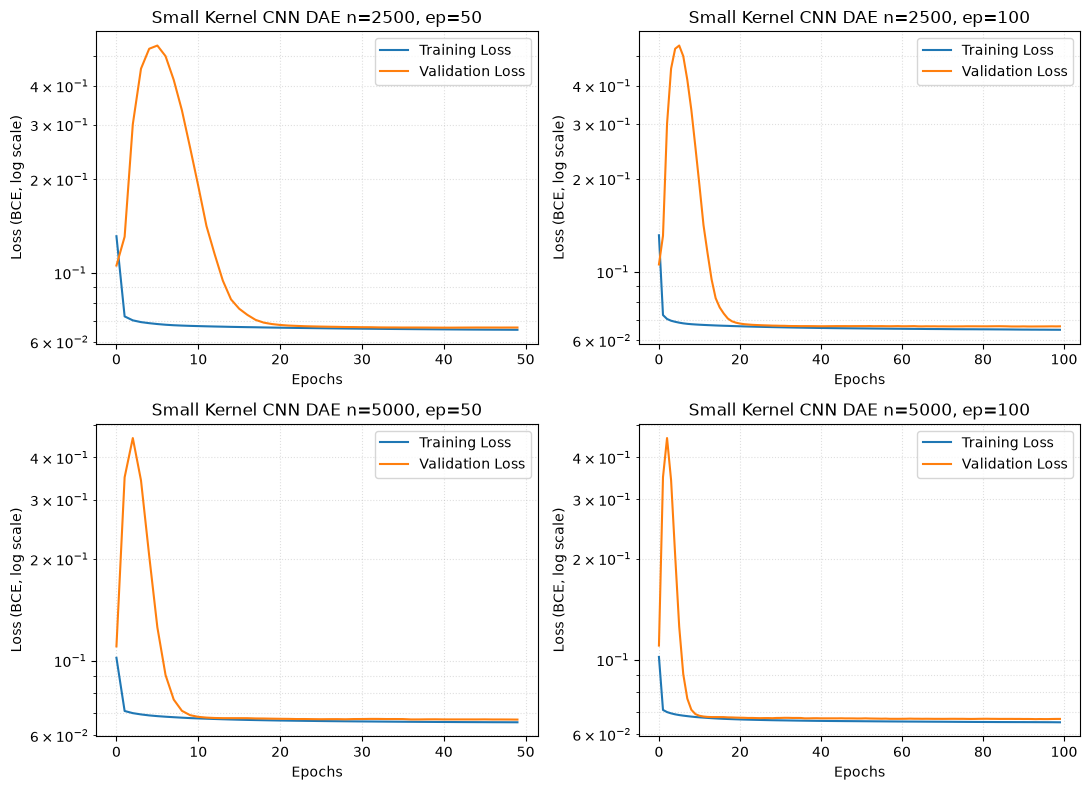

In [9]:
def plot_loss(res, title=""):
    fig, axs = plt.subplots(2, 2, figsize=(11, 8))
    for ax, (k, r) in zip(axs.flat, res.items()):
        ax.plot(r["hist"]["loss"], label="Training Loss")
        ax.plot(r["hist"]["val_loss"], label="Validation Loss")
        ax.set_yscale("log")
        ax.grid(True, which="both", linestyle=":", alpha=0.4)
        ax.set_title(f"{title} n={k[0]}, ep={k[1]}")
        ax.set_xlabel("Epochs"); ax.set_ylabel("Loss (BCE, log scale)"); ax.legend()
    plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

plot_loss(res, "Small Kernel CNN DAE")

## 8. Evaluation 2 – Original / Test (noisy) / Result for digits 0–9

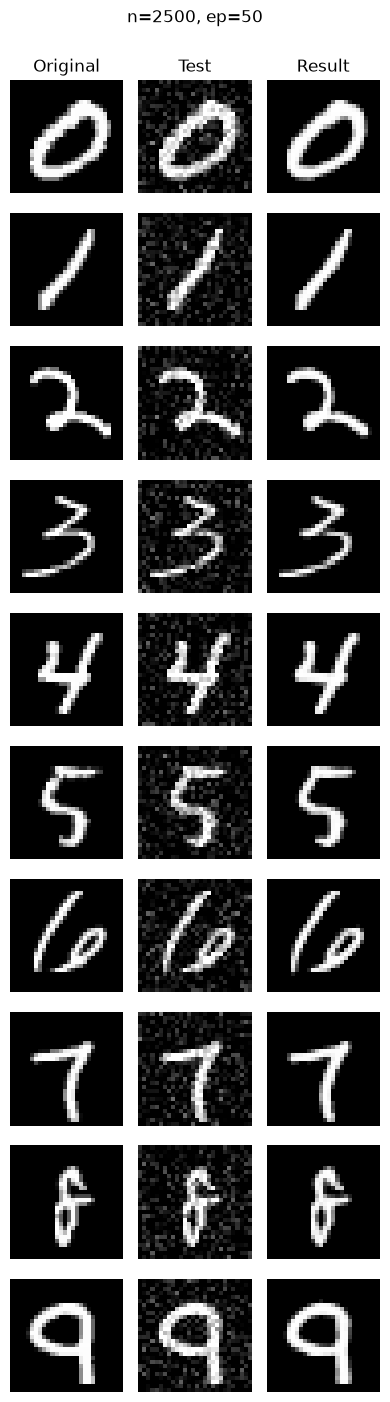

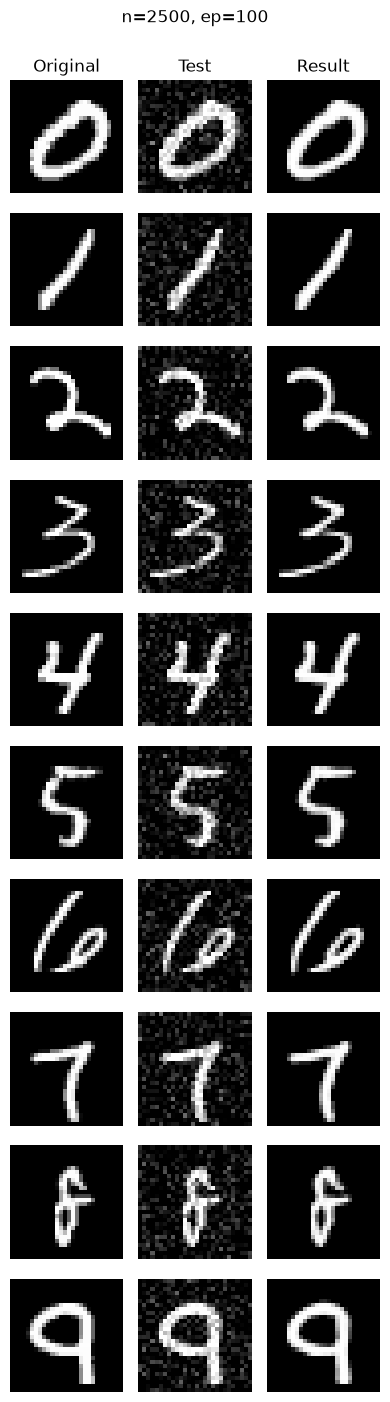

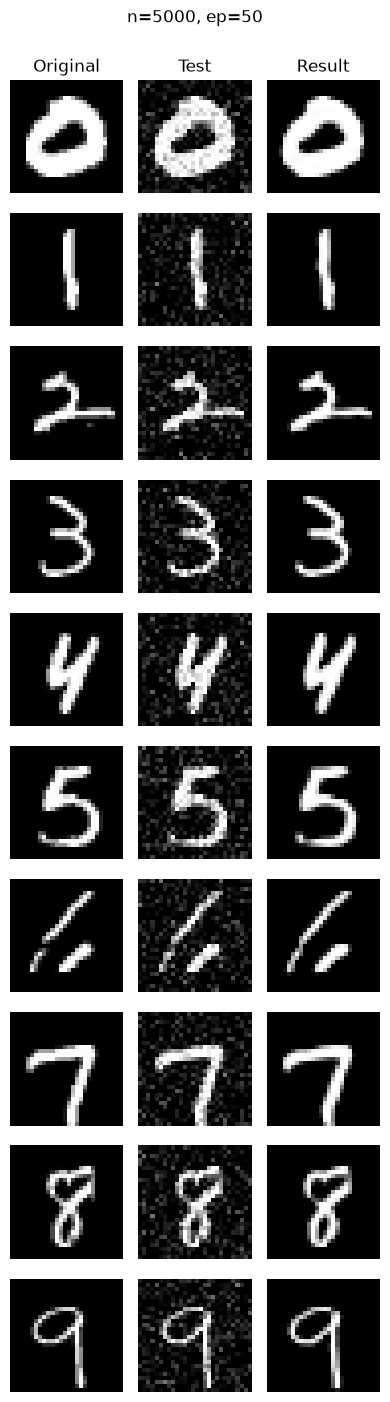

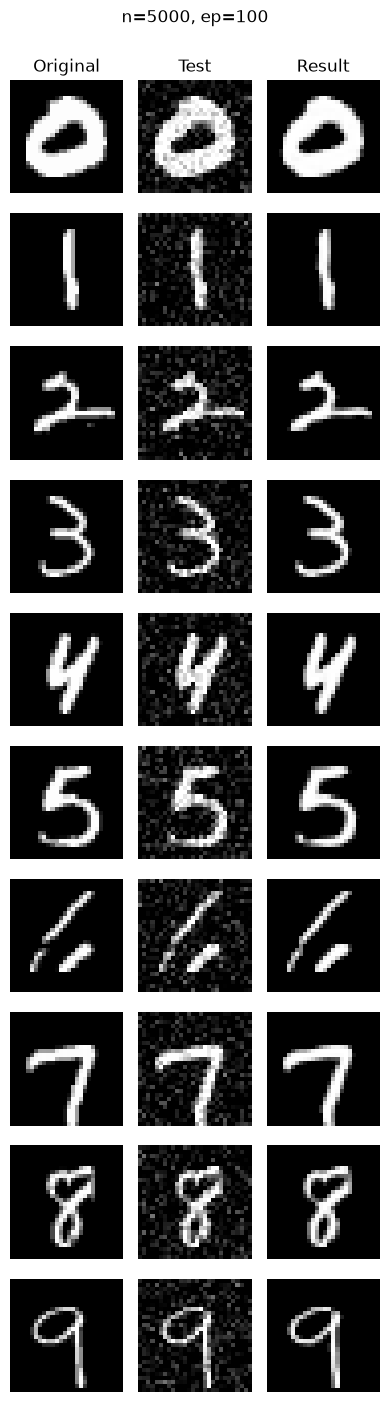

In [10]:
def show_digits(res, key):
    r = res[key]
    fig, axs = plt.subplots(10, 3, figsize=(4, 14))
    for dgt in range(10):
        i = np.where(r["y_te"] == dgt)[0][0]
        for j, (img, t) in enumerate([(r["clean"][i], "Original"),
                                      (r["noisy"][i], "Test"),
                                      (r["recon"][i], "Result")]):
            axs[dgt, j].imshow(img.reshape(28, 28), cmap="gray")
            axs[dgt, j].axis("off")
            if dgt == 0: axs[dgt, j].set_title(t)
    fig.suptitle(f"n={key[0]}, ep={key[1]}", y=1.0)
    plt.tight_layout(); plt.savefig(f"digits_n{key[0]}_ep{key[1]}.png", dpi=150); plt.show()

for key in res:
    show_digits(res, key)

## 9. Evaluation 3 – Confusion matrices (Original vs Noisy vs Denoised)
A small classifier is trained on the clean training data, then asked to classify the three versions of the test images.

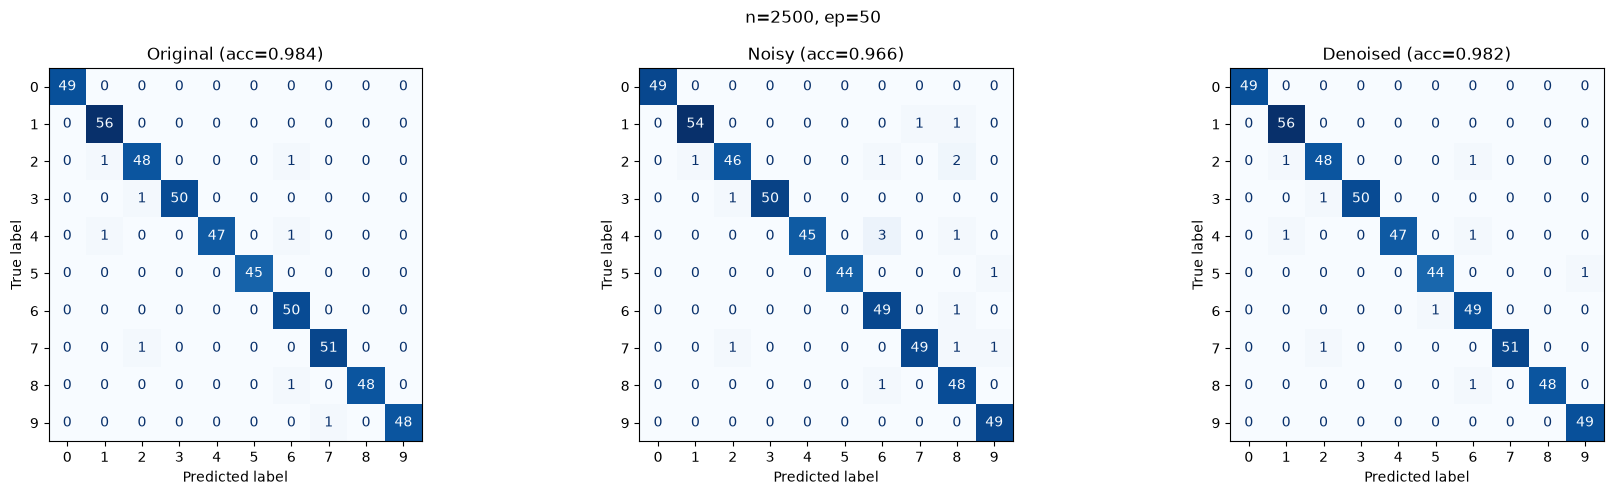

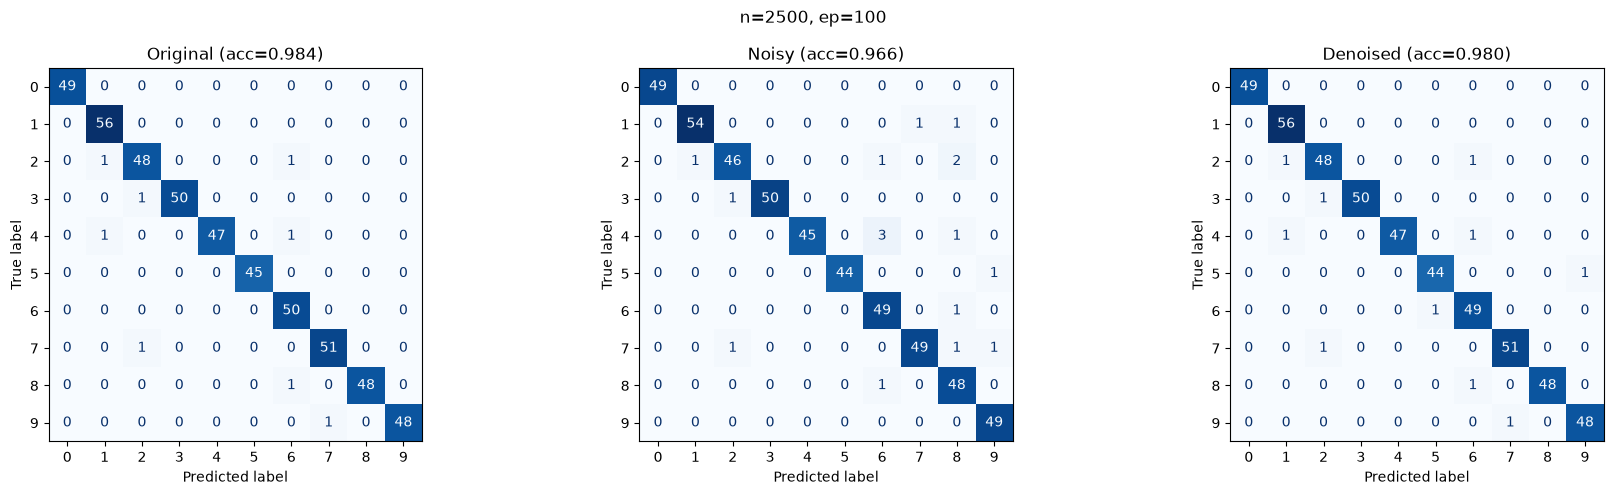

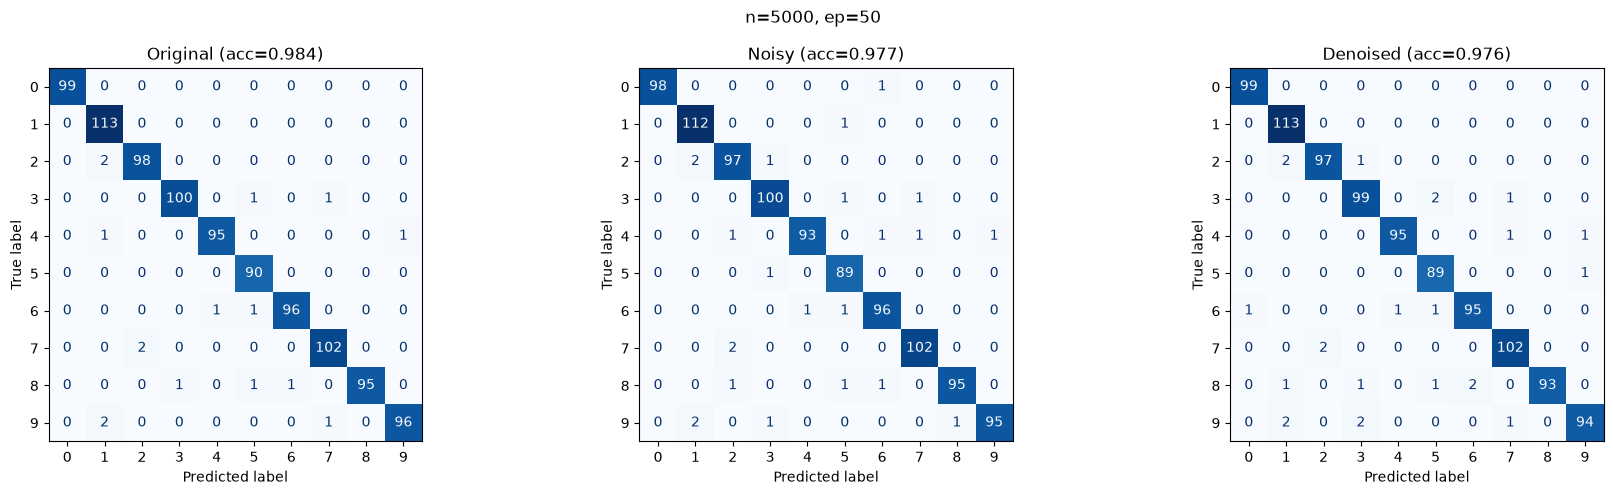

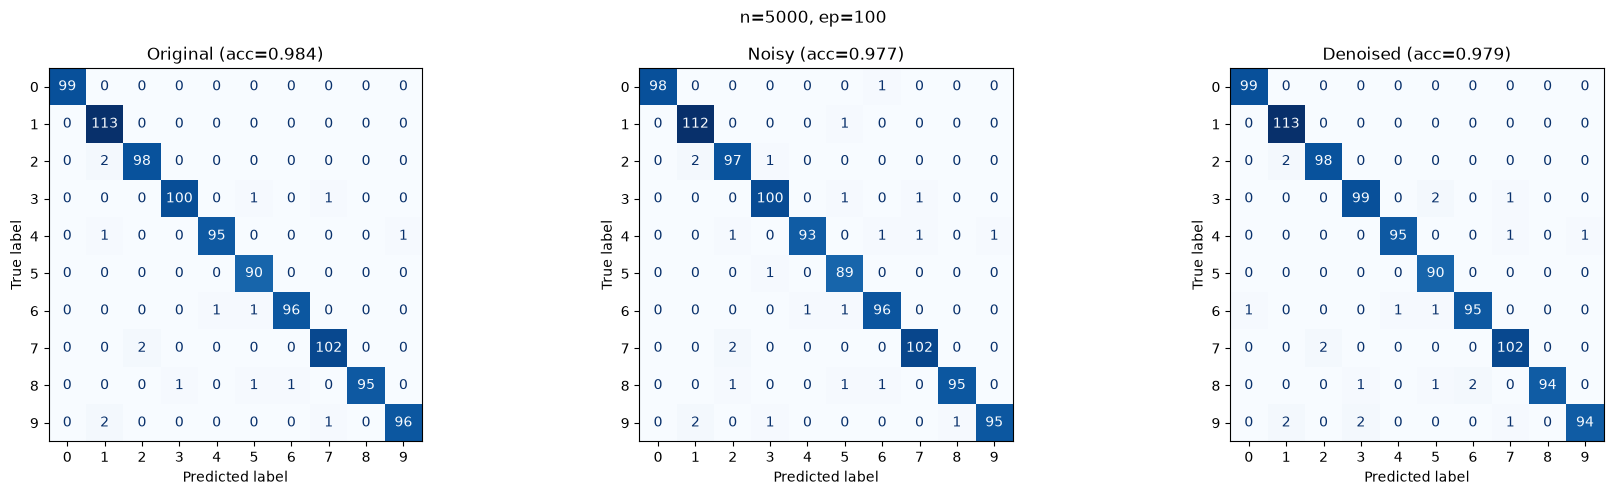

In [11]:
classifiers = {}
def get_clf(n):
    if n not in classifiers:
        X_tr, y_tr, X_val, y_val, *_ = make_splits(n)
        set_seed()
        clf = keras.Sequential([
            layers.Input((28, 28, 1)),
            layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
            layers.BatchNormalization(),
            layers.MaxPooling2D((2, 2)),
            layers.Dropout(0.2),
            layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
            layers.BatchNormalization(),
            layers.MaxPooling2D((2, 2)),
            layers.Dropout(0.2),
            layers.Flatten(),
            layers.Dense(128, activation="relu"),
            layers.Dropout(0.3),
            layers.Dense(10, activation="softmax")
        ])
        clf.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])
        clf.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                epochs=25, batch_size=32, verbose=0)
        classifiers[n] = clf
    return classifiers[n]

def show_confusion(res, key):
    r = res[key]; clf = get_clf(key[0])
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (name, imgs) in zip(axs, [("Original", r["clean"]),
                                      ("Noisy", r["noisy"]),
                                      ("Denoised", r["recon"])]):
        pred = clf.predict(imgs, verbose=0).argmax(1)
        acc = accuracy_score(r["y_te"], pred)
        ConfusionMatrixDisplay(confusion_matrix(r["y_te"], pred)).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"{name} (acc={acc:.3f})")
    fig.suptitle(f"n={key[0]}, ep={key[1]}")
    plt.tight_layout(); plt.savefig(f"confusion_n{key[0]}_ep{key[1]}.png", dpi=150); plt.show()

for key in res:
    show_confusion(res, key)

## 10. Metrics table (MSE · PSNR · SSIM · Accuracy)

In [12]:
def make_table(res):
    rows = []
    for (n, ep), r in res.items():
        clf = get_clf(n)
        cl, nz, rc = r["clean"], r["noisy"], r["recon"]
        rows.append({
            "size": n, "epochs": ep,
            "MSE noisy": np.mean((nz - cl) ** 2), "MSE denoised": r["mse"],
            "PSNR noisy":    np.mean([psnr(p, q, data_range=1) for p, q in zip(cl, nz)]),
            "PSNR denoised": np.mean([psnr(p, q, data_range=1) for p, q in zip(cl, rc)]),
            "SSIM noisy":    np.mean([ssim(p.squeeze(), q.squeeze(), data_range=1) for p, q in zip(cl, nz)]),
            "SSIM denoised": np.mean([ssim(p.squeeze(), q.squeeze(), data_range=1) for p, q in zip(cl, rc)]),
            "Acc noisy":    accuracy_score(r["y_te"], clf.predict(nz, verbose=0).argmax(1)),
            "Acc denoised": accuracy_score(r["y_te"], clf.predict(rc, verbose=0).argmax(1)),
        })
    return pd.DataFrame(rows).round(4)

# 1. Summary table across the 4 runs
table = make_table(res)
table.to_csv("results_table.csv", index=False)
print("=== Summary Table ===")
display(table)

# 2. Per-epoch table (every epoch 1 to 100 for all runs)
def make_epoch_table(res):
    rows = []
    for (n, ep), r in res.items():
        losses = r["hist"]["loss"]
        val_losses = r["hist"].get("val_loss", [])
        for i, (tl, vl) in enumerate(zip(losses, val_losses)):
            rows.append({
                "size": n,
                "total_epochs": ep,
                "epoch": i + 1,
                "train_loss": round(float(tl), 6),
                "val_loss": round(float(vl), 6)
            })
    return pd.DataFrame(rows)

epoch_df = make_epoch_table(res)
epoch_df.to_csv("epochs_1_to_100_results.csv", index=False)
print(f"Saved 'epochs_1_to_100_results.csv' ({len(epoch_df)} rows: all epochs 1 to 100 for each run)")

# 3. Wide per-epoch table (Epoch 1..100 as rows, each run's train & val loss as columns)
wide_dict = {"epoch": list(range(1, 101))}
for (n, ep), r in res.items():
    tr_col = f"train_loss_n{n}_ep{ep}"
    val_col = f"val_loss_n{n}_ep{ep}"
    tr = [round(float(v), 6) for v in r["hist"]["loss"]]
    vl = [round(float(v), 6) for v in r["hist"]["val_loss"]]
    # Pad to 100 rows with None for 50-epoch runs
    tr += [None] * (100 - len(tr))
    vl += [None] * (100 - len(vl))
    wide_dict[tr_col] = tr
    wide_dict[val_col] = vl

wide_df = pd.DataFrame(wide_dict)
wide_df.to_csv("epochs_1_to_100_wide.csv", index=False)
print("Saved 'epochs_1_to_100_wide.csv' (Epoch 1 to 100 side-by-side comparison)")
display(wide_df.head(10))

=== Summary Table ===


,size,epochs,MSE noisy,MSE denoised,PSNR noisy,PSNR denoised,SSIM noisy,SSIM denoised,Acc noisy,Acc denoised
0,2500,50,0.0121,0.0019,19.1865,27.3977,0.6584,0.9741,0.966,0.982
1,2500,100,0.0121,0.0019,19.1865,27.5198,0.6584,0.9740,0.966,0.980
2,5000,50,0.0121,0.0019,19.1955,27.3665,0.6534,0.9733,0.977,0.976
3,5000,100,0.0121,0.0019,19.1955,27.5027,0.6534,0.9737,0.977,0.979


Saved 'epochs_1_to_100_results.csv' (300 rows: all epochs 1 to 100 for each run)
Saved 'epochs_1_to_100_wide.csv' (Epoch 1 to 100 side-by-side comparison)


,epoch,train_loss_n2500_ep50,val_loss_n2500_ep50,train_loss_n2500_ep100,val_loss_n2500_ep100,train_loss_n5000_ep50,val_loss_n5000_ep50,train_loss_n5000_ep100,val_loss_n5000_ep100
0,1,0.131211,0.105549,0.131211,0.105549,0.101893,0.110134,0.101893,0.110134
1,2,0.072404,0.130699,0.072404,0.130699,0.070858,0.349289,0.070858,0.349289
2,3,0.070325,0.300886,0.070325,0.300886,0.069826,0.456629,0.069826,0.456629
3,4,0.069408,0.454317,0.069408,0.454317,0.069218,0.342039,0.069218,0.342039
4,5,0.068863,0.526595,0.068863,0.526595,0.068753,0.204669,0.068753,0.204669
5,6,0.068422,0.539332,0.068422,0.539332,0.068413,0.125448,0.068413,0.125448
6,7,0.068071,0.498553,0.068071,0.498553,0.068143,0.090577,0.068143,0.090577
7,8,0.067820,0.418060,0.067820,0.418060,0.067913,0.076600,0.067913,0.076600
8,9,0.067642,0.333692,0.067642,0.333692,0.067696,0.070939,0.067696,0.070939
9,10,0.067500,0.253059,0.067500,0.253059,0.067507,0.068864,0.067507,0.068864


## 10b. Use the ENCODER – the compressed code (bottleneck) of the trained model
The encoder compresses the input from 28×28×1 (784 values) to 14×14×64 (12,544 feature activations).


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ enc_conv (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_pool (MaxPooling2D)         │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_bottleneck (Conv2D)      │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 14, 14, 64)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,200 (75.00 KB)

 Trainable params: 19,008 (74.25 KB)

 Non-trainable params: 192 (768.00 B)

code shape: (1000, 14, 14, 64) -> bottleneck features per image


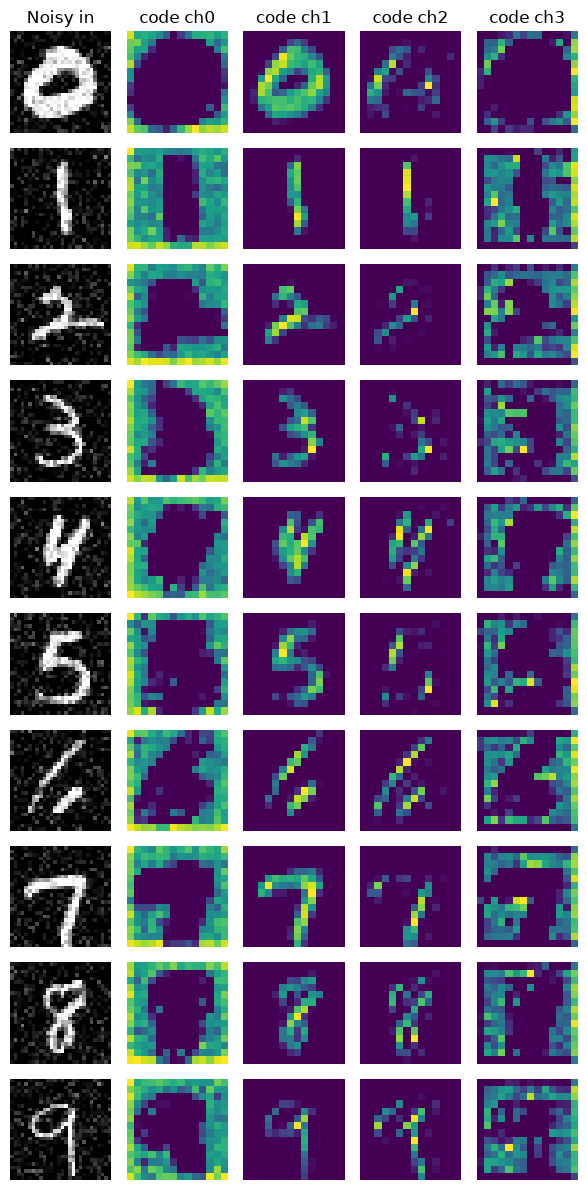

In [13]:
key = (5000, 100)                       # which trained run to inspect
model = res[key]["model"]
encoder = res[key]["encoder"]          # access the trained encoder submodel
encoder.summary()

r = res[key]
codes = encoder.predict(r["noisy"], verbose=0)
print("code shape:", codes.shape, "-> bottleneck features per image")

fig, axs = plt.subplots(10, 5, figsize=(6, 12))
for dgt in range(10):
    i = np.where(r["y_te"] == dgt)[0][0]
    axs[dgt, 0].imshow(r["noisy"][i].squeeze(), cmap="gray")
    if dgt == 0: axs[dgt, 0].set_title("Noisy in")
    for ch in range(4):
        axs[dgt, ch + 1].imshow(codes[i, :, :, ch], cmap="viridis")
        if dgt == 0: axs[dgt, ch + 1].set_title(f"code ch{ch}")
    for a_ in axs[dgt]: a_.axis("off")
plt.tight_layout(); plt.savefig("encoder_codes.png", dpi=150); plt.show()


## 11. Save everything (graphs + table) for the report

In [14]:
import shutil
os.makedirs("results", exist_ok=True)
for f in glob.glob("*.png") + glob.glob("*.csv"):
    shutil.copy(f, "results")
shutil.make_archive("results", "zip", "results")
try:
    from google.colab import files          # only exists on Colab
    files.download("results.zip")
except ImportError:
    print("Saved to the results/ folder and results.zip next to this file")

Saved to the results/ folder and results.zip next to this file
